# Fine-tuning para classificação de decisões judiciais de Habeas Corpus do STJ

**Período:** 01/2021 a 06/2026

**Dataset:** 6.220 registros de decisões de HC

**Aceleradores de Hardware - Ordem de Custo**

1. CPU
2. GPUs: T4
2. GPUs: L4
4. TPU v5e-1
5. TPU v6e-1
6. GPUs: A100
7. GPUs: G4
8. GPUs: H100

##Parametrização

In [ ]:
BASE_PATH_GENERAL = '/content/drive/MyDrive/_Mestrado PUCPR/'
BASE_PATH_DATASET = f'{BASE_PATH_GENERAL}Datasets/'
#MODEL_CHECKPOINT = 'raquelsilveira/legalbertpt_fp'
#MODEL_CHECKPOINT = 'neuralmind/bert-large-portuguese-cased' #BERTimbau
MODEL_CHECKPOINT = 'rufimelo/Legal-BERTimbau-large'
MODEL_NAME_SAVED = 'decision_HC_STJ_finetuned_large-portuguese-cased'

TEST_SIZE_SPLIT = 0.35
RANDOM_SEED = 42
EPOCHS = 200
LAYERS_TO_FREEZE = 24
LEARNING_RATE = 2e-5
BATCH_SIZE = 16
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
EARLY_STOPPING = 5
class_names = ['Desfavorável ao Réu', 'Favorável ao Réu']
MAX_LEN = 512

# Performance knobs
NUM_WORKERS = 2
USE_TORCH_COMPILE = False

In [2]:
# Silenciar warings
import warnings
warnings.filterwarnings('ignore')

In [3]:
#!pip install transformers

In [4]:
import numpy as np
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from pylab import rcParams

In [5]:
# Padronização dos Gráficos
%config InlineBackend.figure_format='retina'

sns.set(style='whitegrid', palette='muted', font_scale=1.2)
#COLORS_PALETTE = ["#01BEFE", "#FFDD00", "#FF7D00", "#FF006D", "#ADFF02", "#8F00FF"]

COLORS_PALETTE = ["#0098CC", "#CCA100", "#CC6400", "#CC0057", "#8ACC02", "#7200CC"]
sns.set_palette(sns.color_palette(COLORS_PALETTE))
rcParams['figure.figsize'] = 12, 8

In [6]:
# Garante que processos que dependem de aleatoriedade gerem sempre o mesmo resultado,
#   caso ocorra a execução do notebook novamente.

np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Permite kernels mais rápidos em GPUs NVIDIA recentes sem afetar a precisão final para este caso
if device.type == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
# O pré-processamento textual já foi realizado, porém, se for necessário remover
#   a pontuação (no caso de testes com modelos rasos), o pré-processamento pode
#   ser acionando novamente com o parâmetro mantem_pontuacao = 'N'.

# %run "{BASE_PATH_GENERAL}libs/preprocessing_pucpr.ipynb"

In [10]:
import pandas as pd

# Define file paths
file_path = f"{BASE_PATH_DATASET}preprocessed_acordaos_HC_undersampling_2021_2026.csv"

# Load each CSV file into a dataframe
try:
    df = pd.read_csv(file_path, sep=';')
    print(f"Successfully loaded {file_path} into dataframe 'preprocessed ACÓRDÃOS 2025'")
    print(df.shape)
    display(df.head(3))
except FileNotFoundError:
    print(f"Error: File not found at {file_path}")
except Exception as e:
    print(f"An error occurred while loading {file_path}: {e}")

Successfully loaded /content/drive/MyDrive/_Mestrado PUCPR/Datasets/preprocessed_acordaos_HC_undersampling_2021_2026.csv into dataframe 'preprocessed ACÓRDÃOS 2025'
(6220, 22)


,SEQDOCUMENTO,DATAPUBLICACAO,TIPODOCUMENTO,NUMEROREGISTRO,DATARECEBIMENTO,DATADISTRIBUICAO,MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,...,TIPOPROCESSO,NUMEROPROCESSO,ACORDAO,EMENTA,RELATORIO,VOTO,DECISAO,DECISAO_FAVORAVEL,SG_RECURSO,DS_RECURSO
0,371146240,2026-04-29,ACÓRDÃO,202600728053,2026-03-02,2026-03-03,RIBEIRO DANTAS,AGRG,Concedendo,NaN,...,HC,1077232,Vistos e relatados estes autos em que são part...,Direito penal. Agravo regimental em habeas cor...,Trata-se de agravo regimental interposto por E...,"Preliminarmente, observa-se que a defesa busca...",NaN,S,AGRG,AGRAVO REGIMENTAL
1,220475855,2023-12-13,ACÓRDÃO,202303259474,2023-09-08,2023-09-08,ROGERIO SCHIETTI CRUZ,AGRAVO REGIMENTAL,Concedendo Parcialmente,NaN,...,HC,852949,NaN,VOTO-VISTAO SENHOR MINISTRO ROGERIO SCHIETTI C...,A EXMA. SRA. MINISTRA LAURITA VAZ:Trata-se de ...,A EXMA. SRA. MINISTRA LAURITA VAZ (Relatora):V...,NaN,S,AGRG,AGRAVO REGIMENTAL
2,282354653,2024-11-19,ACÓRDÃO,202400300710,2024-02-06,NaN,DANIELA TEIXEIRA,NaN,Concedendo,NaN,...,HC,888358,Vistos e relatados estes autos em que são part...,DIREITO PENAL. HABEAS CORPUS. TRÁFICO DE ENTOR...,Trata-se de habeas corpus impetrado em favor d...,"A Terceira Seção desta Corte, seguindo entendi...",NaN,S,DIRETO,TRÂMITE DIRETO


In [11]:
#Listar os nomes unícos dos ministros
ministros_unicos = df['MINISTRO'].unique()
print(ministros_unicos)

['RIBEIRO DANTAS' 'ROGERIO SCHIETTI CRUZ' 'DANIELA TEIXEIRA'
 'ANTONIO SALDANHA PALHEIRO' 'SEBASTIÃO REIS JÚNIOR' 'JOEL ILAN PACIORNIK'
 'MESSOD AZULAY NETO' 'OTÁVIO DE ALMEIDA TOLEDO (DESE'
 'REYNALDO SOARES DA FONSECA' 'JESUÍNO RISSATO (DESEMBARGADOR'
 'OLINDO MENEZES (DESEMBARGADOR ' 'LAURITA VAZ' 'FELIX FISCHER'
 'MARIA MARLUCE CALDAS' 'JOÃO OTÁVIO DE NORONHA' 'OG FERNANDES'
 'JORGE MUSSI' 'CARLOS CINI MARCHIONATTI (DESE' 'LUIS FELIPE SALOMÃO'
 'TEODORO SILVA SANTOS' 'CARLOS PIRES BRANDÃO' 'NEFI CORDEIRO'
 'HUMBERTO MARTINS' 'JOÃO BATISTA MOREIRA  (DESEMBA'
 'PAULO DE TARSO SANSEVERINO' 'REGINA HELENA COSTA' 'SÉRGIO KUKINA'
 'NANCY ANDRIGHI' 'FRANCISCO FALCÃO' 'PAULO SÉRGIO DOMINGUES']


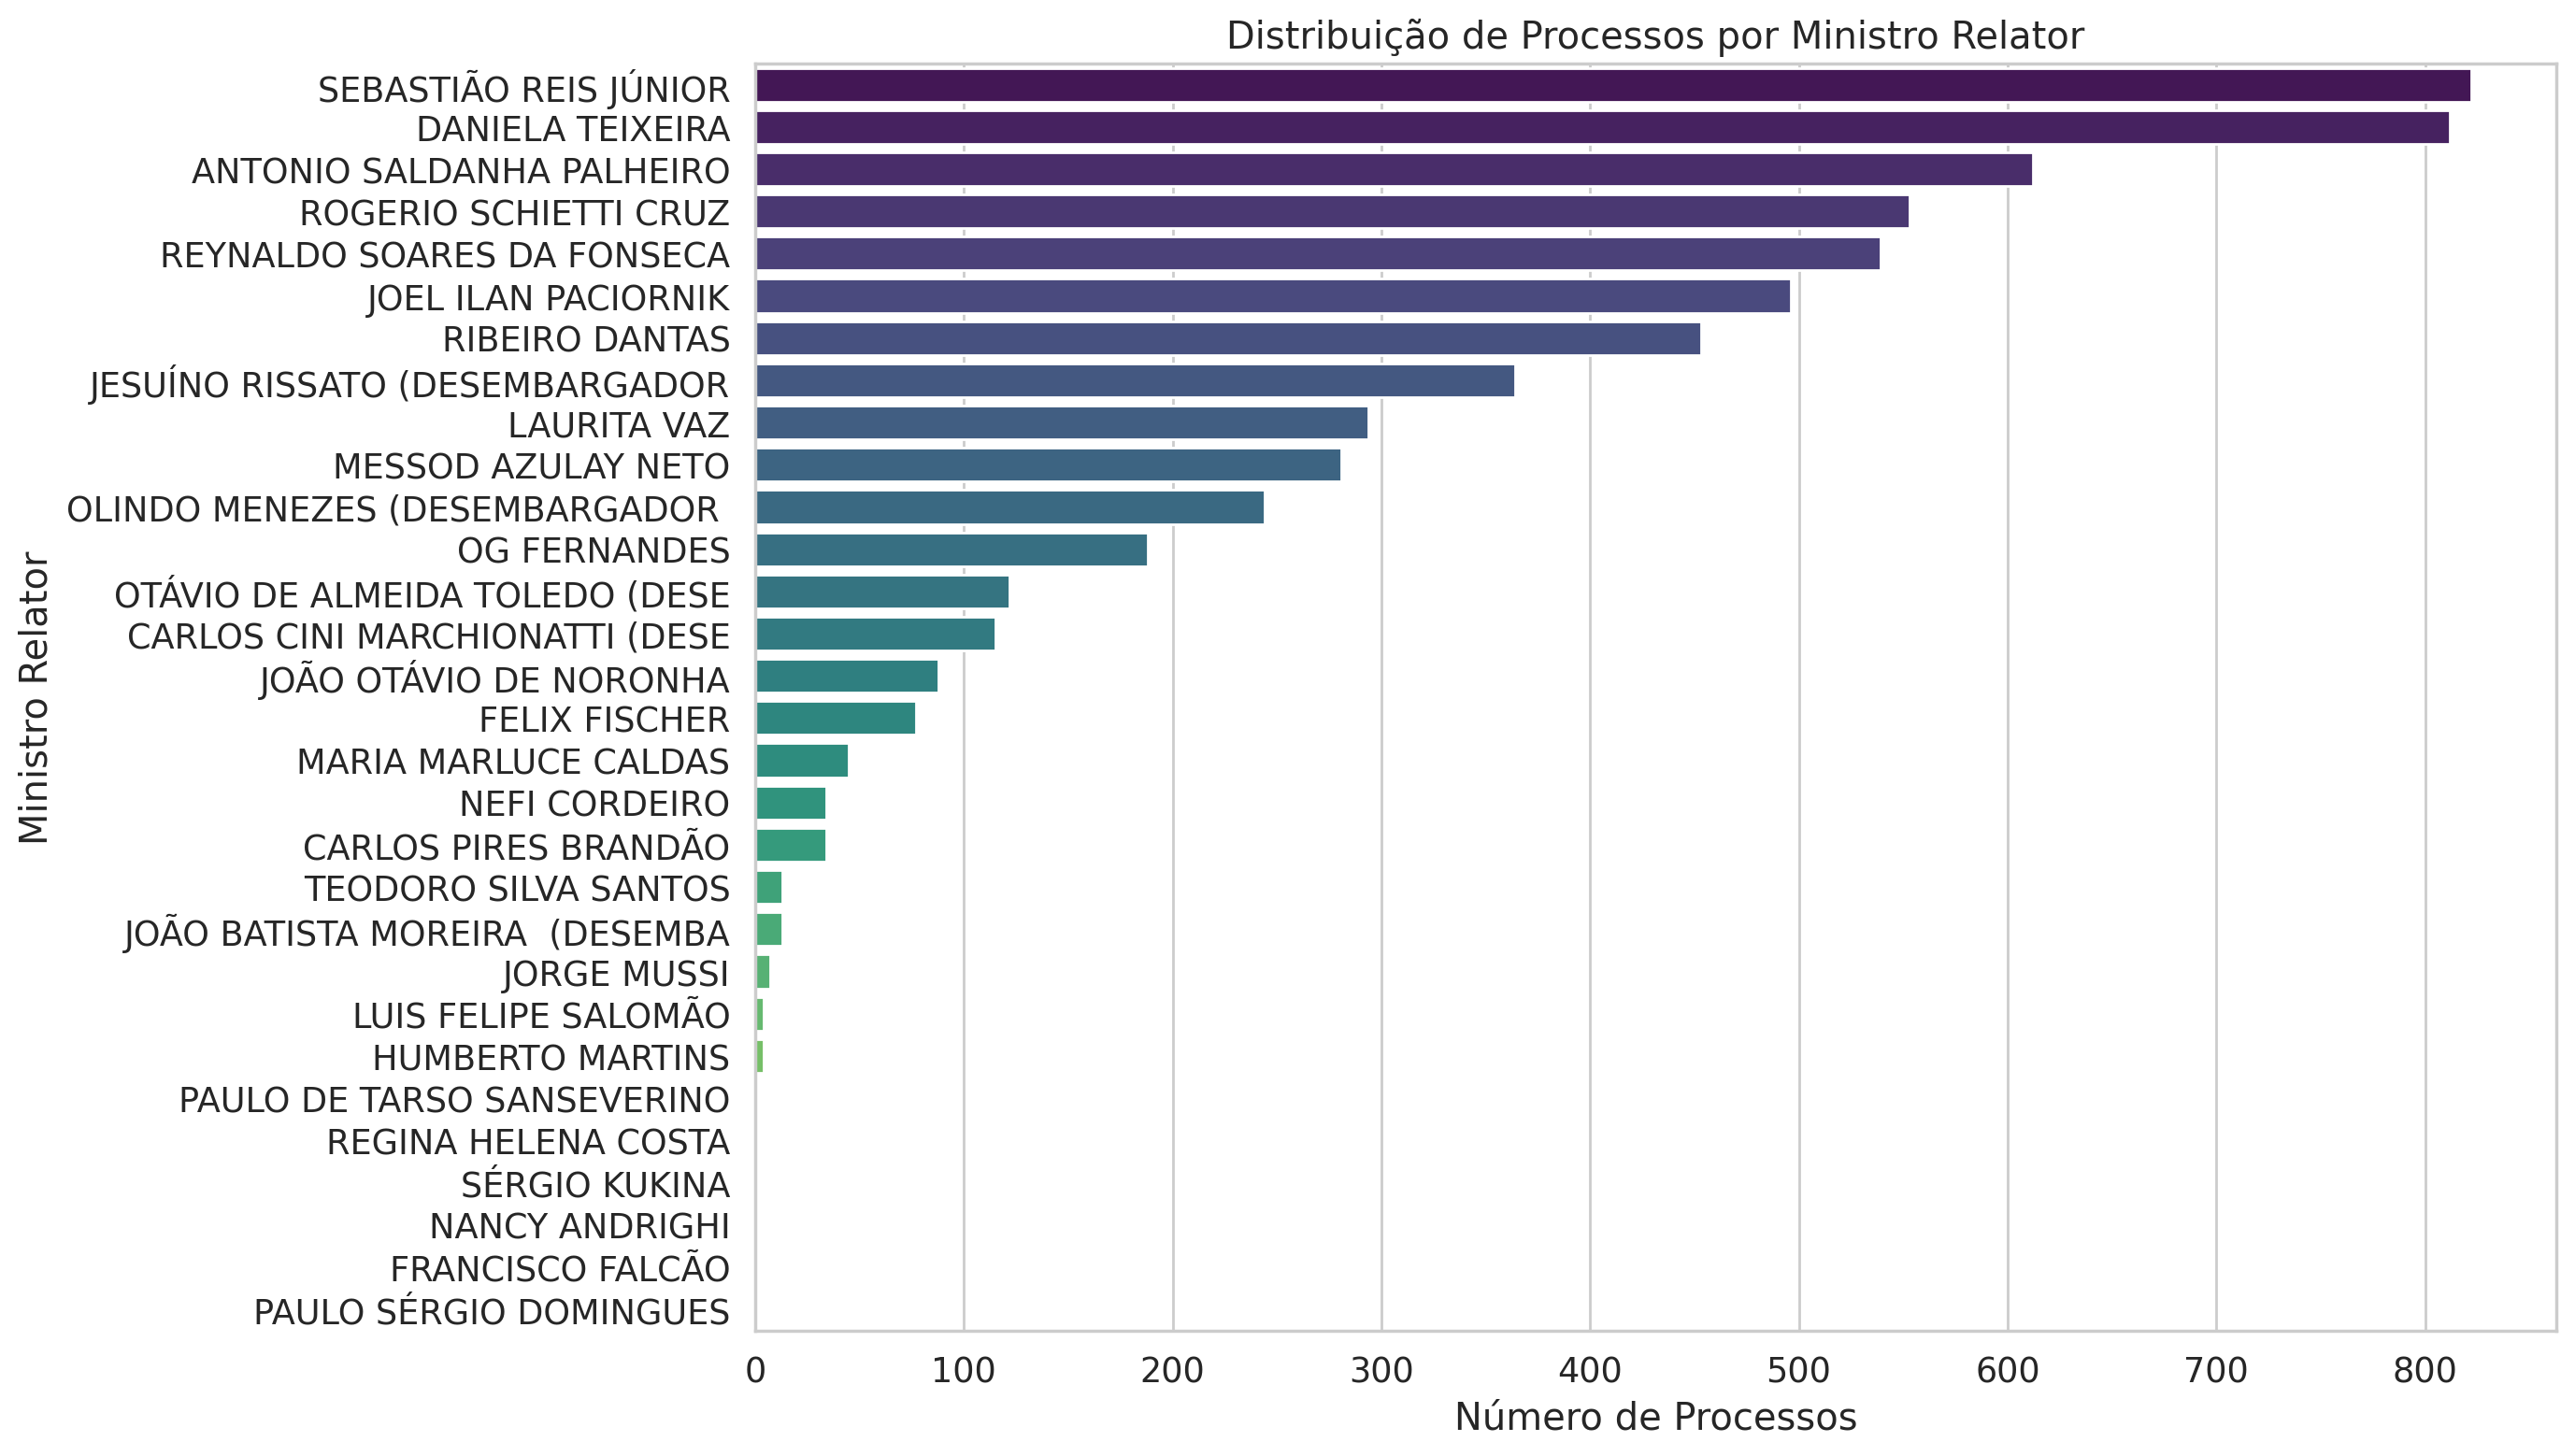

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Procura a coluna correspondente ao Ministro/Relator
possible_columns = ['MINISTRO', 'NM_MINISTRO']
minister_col = None

for col in possible_columns:
    if col in df.columns:
        minister_col = col
        break

if minister_col:
    plt.figure(figsize=(14, 8))
    # Calcula a distribuição de processos
    minister_counts = df[minister_col].value_counts()

    # Gera o gráfico de barras horizontais
    sns.barplot(y=minister_counts.index, x=minister_counts.values, palette='viridis')
    plt.title('Distribuição de Processos por Ministro Relator')
    plt.xlabel('Número de Processos')
    plt.ylabel('Ministro Relator')
    plt.tight_layout()
    plt.show()
else:
    print("Não foi possível identificar a coluna correspondente ao Ministro Relator. Por favor, verifique o nome correto.")
    print("Colunas disponíveis no dataset:", df.columns.tolist())

Total de registros original: 6220
Total de registros após balanceamento e exclusão de desembargadores: 3728


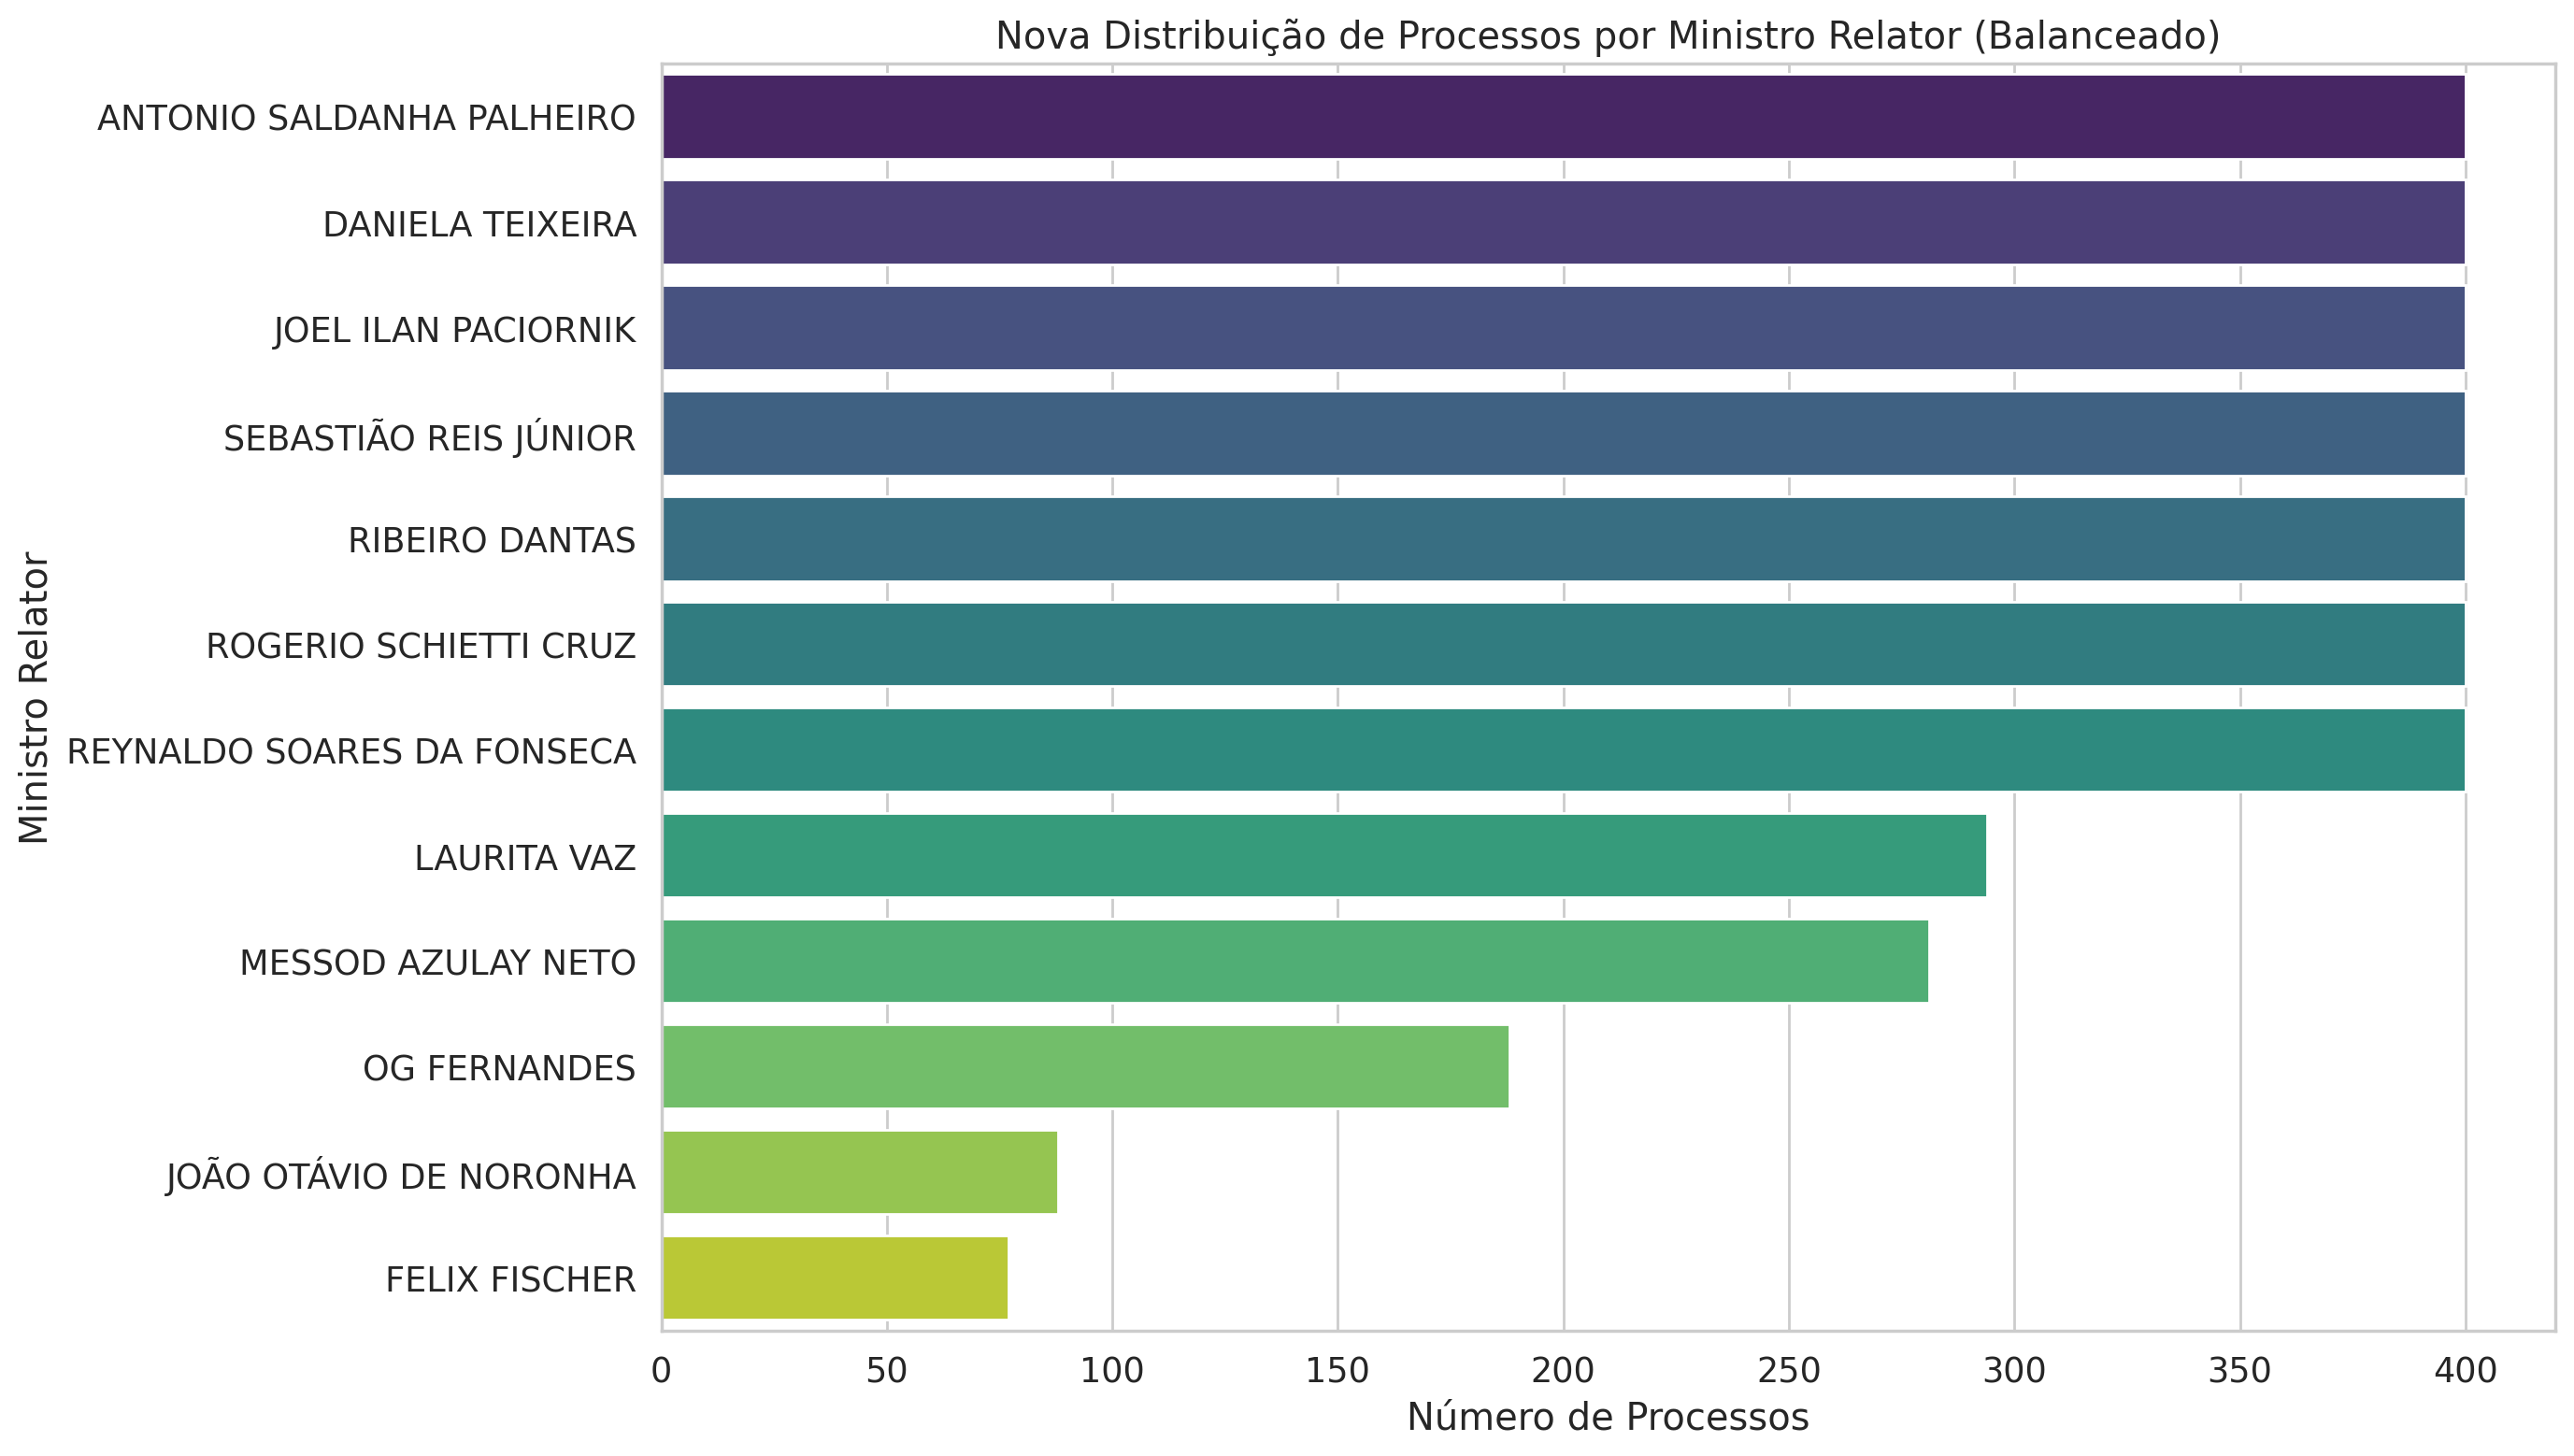

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

min_processos = 50
max_processos = 400

print(f"Total de registros original: {len(df)}")

# 1. Remoção de Desembargadores: Exclui relatores que são desembargadores convocados
# Adicionado regex=False para evitar o erro com o parênteses aberto
df = df[~df[minister_col].str.contains(' (DESE', case=False, na=False, regex=False)].copy()

# 2. Corte Mínimo: Identifica e filtra ministros com pelo menos 50 processos
contagem = df[minister_col].value_counts()
ministros_validos = contagem[contagem >= min_processos].index
df_filtrado = df[df[minister_col].isin(ministros_validos)].copy()

# 3. Teto Máximo: Limita a 400 processos por ministro através de amostragem aleatória
def sample_minister(group):
    if len(group) > max_processos:
        return group.sample(n=max_processos, random_state=RANDOM_SEED)
    return group

# Aplica o limite por grupo de ministros
df_balanceado = df_filtrado.groupby(minister_col, group_keys=False).apply(sample_minister)

# Atualiza o dataframe principal
df = df_balanceado.reset_index(drop=True)

print(f"Total de registros após balanceamento e exclusão de desembargadores: {len(df)}")

# 4. Visualiza a nova distribuição
plt.figure(figsize=(14, 8))
minister_counts_new = df[minister_col].value_counts()
sns.barplot(y=minister_counts_new.index, x=minister_counts_new.values, palette='viridis')
plt.title('Nova Distribuição de Processos por Ministro Relator (Balanceado)')
plt.xlabel('Número de Processos')
plt.ylabel('Ministro Relator')
plt.tight_layout()
plt.show()

### Justificativa Metodológica: Mitigação de Viés Representacional e Balanceamento de Autoria

A etapa de pré-processamento supracitada aplica uma técnica de amostragem híbrida com o intuito de mitigar potenciais vieses algorítmicos (*algorithmic bias*) decorrentes da distribuição assimétrica do volume processual entre os relatores. A literatura em Processamento de Linguagem Natural (PLN) aplicado ao domínio jurídico adverte para o risco de modelos baseados na arquitetura *Transformer* (como o BERT) internalizarem padrões estilométricos (estilo de escrita) ou correlações espúrias associadas a magistrados super-representados no *dataset*, em detrimento do efetivo contexto semântico-jurídico da decisão.

A estratégia metodológica adotada divide-se em três frentes complementares:
1. **Poda da Cauda Longa (Corte Mínimo):** Atua na eliminação de ruído estatístico. Relatores com um número ínfimo de acórdãos não oferecem suporte empírico suficiente para que a rede neural generalize seus padrões linguísticos de forma confiável, justificando sua exclusão.
2. **Subamostragem Aleatória (*Random Undersampling* com Teto Máximo):** Assegura a equidade representacional (*representational fairness*). Ao limitar o número máximo de amostras por relator, previne-se o *overfitting* em características idiossincráticas da redação dos ministros mais produtivos.
3. **Exclusão de Desembargadores Convocados:** Magistrados convocados temporariamente apresentam assinaturas estilométricas distintas dos membros titulares da Corte, o que pode introduzir variações indesejadas no vocabulário. Sua remoção contribui para a homogeneização estrutural da amostra.

Por meio desse triplo filtro de controle e balanceamento, busca-se garantir que as representações vetoriais (*embeddings*) aprendidas durante a etapa de *fine-tuning* se concentrem nos fundamentos jurídicos que determinam a concessão ou denegação do Habeas Corpus, promovendo maior robustez e capacidade de generalização ao modelo preditivo.

In [14]:
total   = df.shape[0]
label_s = df[df['DECISAO_FAVORAVEL']  == 'S'].shape[0]
label_n = df[df['DECISAO_FAVORAVEL']  == 'N'].shape[0]

print(f'TOTAL  : {total}')
print(f'LABEL S: {label_s} - % {round(label_s/total*100, 2)}')
print(f'LABEL N: {label_n} - % {round(label_n/total*100, 2)}')

TOTAL  : 3728
LABEL S: 1679 - % 45.04
LABEL N: 2049 - % 54.96


In [15]:
# Function para converter a decisão em num valor contínuo
def cast_decisao_to_int(decisao_favoravel):

    # Convert to class
    if decisao_favoravel == 'S':
        return 1
    else:
        return 0

# Apply to the dataset
df['classe'] = df.DECISAO_FAVORAVEL.apply(cast_decisao_to_int)

In [16]:
df['classe'].value_counts()

,count
classe,
0,2049
1,1679


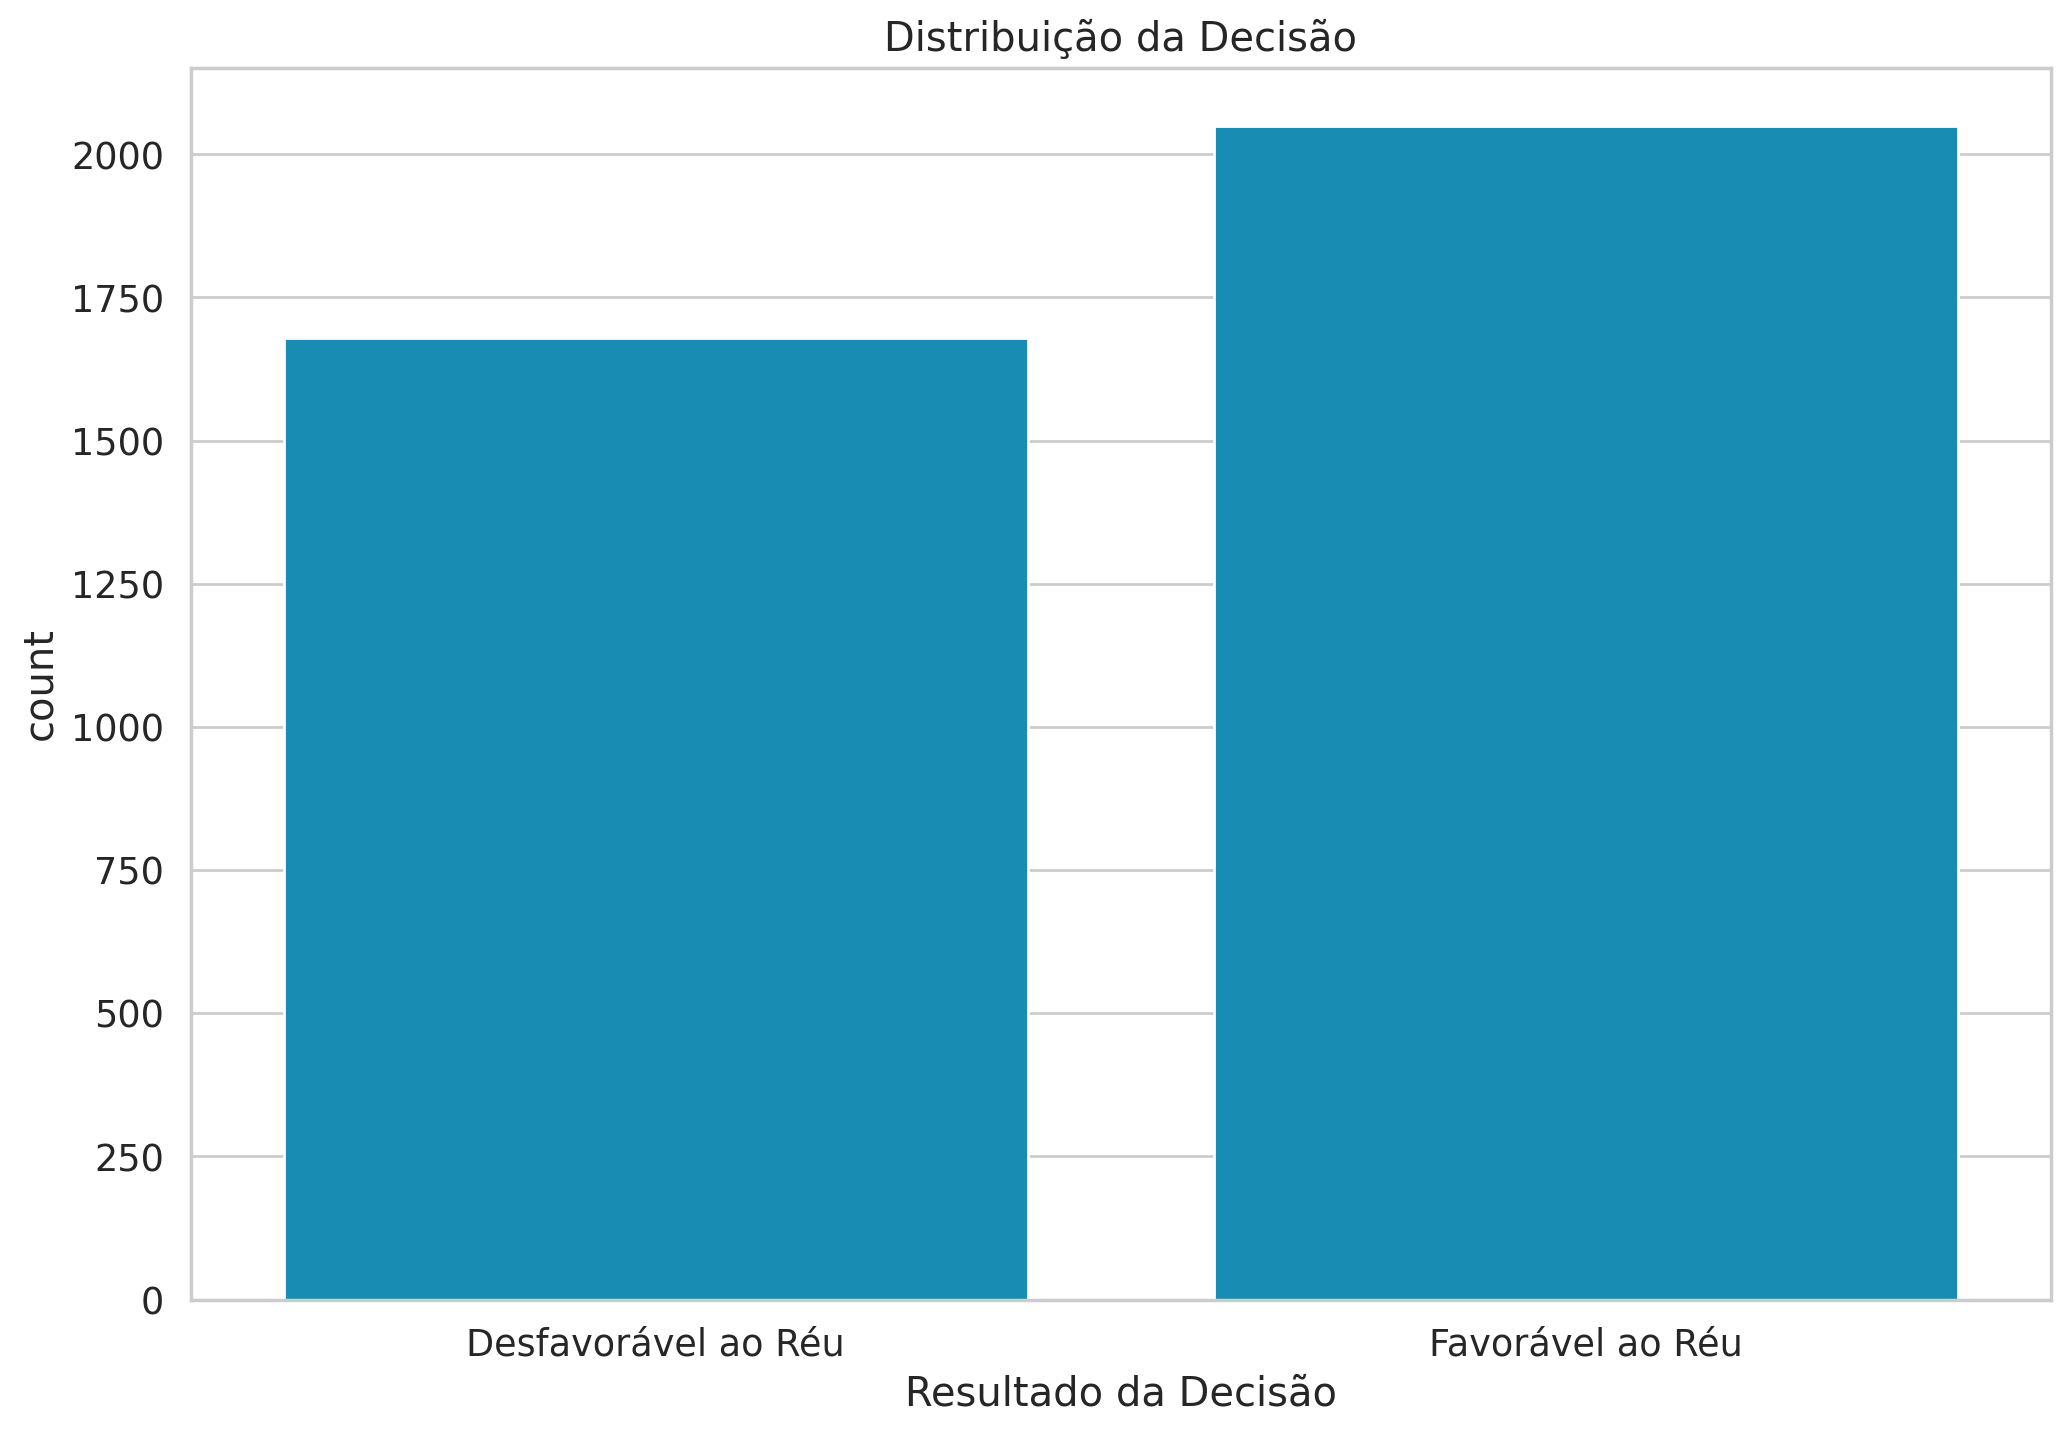

In [17]:
# Garantindo a ordem explícita das classes no gráfico (0 e 1)
ax = sns.countplot(x='classe', data=df, order=[1, 0])

# Fixando os ticks e os rótulos para refletir exatamente os valores 0 e 1
ax.set_xticks([1, 0])
ax.set_xticklabels(['Favorável ao Réu', 'Desfavorável ao Réu'])

plt.xlabel('Resultado da Decisão')
plt.title('Distribuição da Decisão')
plt.show()

In [18]:
# df[df['classe']==1]['RELATORIO'].tolist()[:2]

In [19]:
# df[df['classe']==0]['RELATORIO'].tolist()[:2]

In [20]:
#df['RELATORIO'] = df.RELATORIO.apply(pre_processamento)

In [21]:
# df[df['classe']==1]['RELATORIO'].tolist()[:1]

## BERT

In [ ]:
from transformers import AutoTokenizer

# Tokenizer fast (Rust) reduz bastante o custo de pré-processamento
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT, use_fast=True)

In [23]:
# Some of the common BERT tokens
print(tokenizer.sep_token, tokenizer.sep_token_id) # marker for ending of a sentence
print(tokenizer.cls_token, tokenizer.cls_token_id) # start of each sentence, so BERT knows we’re doing classification
print(tokenizer.pad_token, tokenizer.pad_token_id) # special token for padding
print(tokenizer.unk_token, tokenizer.unk_token_id) # tokens not found in training set

[SEP] 102
[CLS] 101
[PAD] 0
[UNK] 100


BERT works with fixed-length sequences. We’ll use a simple strategy to choose the max length. Let’s store the token length of each review.

In [24]:
# # Store length of each review
# token_lens = []

# # Iterate through the content slide
# for text in df.RELATORIO:
#     #tokens = tokenizer.encode(text, max_length=1024)
#     tokens = tokenizer.encode(text)
#     token_lens.append(len(tokens))

In [25]:
# tokens_test = tokenizer.encode("O Habeas Corpus tem natureza constitucional.", truncation=True, max_length=160)
# #
# tokens_test

In [26]:
# for token in tokens_test:
#     print(f"token: {token} | value: {tokenizer.decode(token)}")

In [27]:
#get_word_from_token_id(101, tokenizer)
# tokenizer.convert_ids_to_tokens(101)

In [28]:
# tokenizer.decode(102)

In [29]:
# plt.figure(figsize=(12, 6))
# # Criando o gráfico de barras (histograma) das contagens absolutas
# sns.histplot(token_lens, bins=50, kde=False, color='#01BEFE')

# plt.title('Distribuição da Quantidade de Tokens por Registro')
# plt.xlabel('Quantidade de Tokens')
# plt.ylabel('Total de Registros')
# plt.xlim([0, 2000]) # Limitando o eixo x conforme o seu distplot anterior
# plt.show()

In [30]:
# plot the distribution of review lengths
# sns.distplot(token_lens)
# plt.xlim([0, 2000]);
# plt.xlabel('Token count')

### Preparing Torch Dataset

To enter data into a PyTorch, we need a more robust data generator class. We will return the review text as well to validate our predictions easily.

###  `HCAcordaoSTJ` (Custom Dataset)

A classe `HCAcordaoSTJ` (que herda de `torch.utils.data.Dataset`) atua como uma **ponte essencial entre os seus dados brutos e o modelo PyTorch/HuggingFace**. A criação desta classe customizada é uma prática padrão e necessária pelos seguintes motivos:

1. **Contrato com o PyTorch (`DataLoader`)**: Para que o `DataLoader` consiga gerenciar os lotes (batches), embaralhar os dados e usar múltiplos processadores, ele precisa saber como interagir com seus dados. O PyTorch exige que você implemente um contrato básico usando dois métodos:
   * `__len__`: Informa ao DataLoader o tamanho total do dataset.
   * `__getitem__`: Ensina o DataLoader a extrair e processar uma única linha (amostra) com base em um índice.

2. **Tokenização *On-the-Fly* (Sob Demanda) e Eficiência de Memória**: O método `__getitem__` aplica o `tokenizer` do HuggingFace individualmente em cada texto *apenas no momento em que a amostra é chamada* durante o treinamento. Em vez de tokenizar todo o seu dataset de 6336 acórdãos de uma vez e armazenar matrizes gigantescas na memória RAM, a transformação é feita lote a lote.

3. **Formatação Exigida pelo BERT**: Modelos da biblioteca `transformers` do HuggingFace não aceitam texto puro (strings). Eles esperam tensores (matrizes numéricas do PyTorch) com chaves muito específicas. O método `__getitem__` prepara e empacota exatamente o que o BERT precisa:
   * **`input_ids`**: O texto mapeado para os números do vocabulário do modelo.
   * **`attention_mask`**: Uma máscara de 1s e 0s que ensina o modelo a olhar apenas para as palavras reais e ignorar os espaços vazios (*padding*).

4. **Padronização Universal (*Padding* e *Truncation*)**: Redes neurais precisam que todas as entradas de um lote tenham o mesmo tamanho matemático. Como os acórdãos variam de tamanho, a classe força com que todos tenham exatamente `max_len` (no seu caso, 512 tokens). Textos menores são preenchidos com zeros (`padding='max_length'`) e textos maiores são cortados (`truncation=True`).

5. **Empacotamento dos Alvos (*Targets*)**: Além de formatar a entrada para o HuggingFace, a classe converte as suas classes (0 ou 1) no formato `torch.long`, que é o tipo de dado estritamente exigido pela função de perda (`CrossEntropyLoss`) do PyTorch durante a etapa de otimização.

Em resumo, o `HCAcordaoSTJ` é o "tradutor" que pega suas strings do Pandas e as transforma perfeitamente no idioma matemático e estrutural que o BERT e o PyTorch entendem.

In [ ]:
from typing import Dict, Union
from torch.utils.data import Dataset

class HCAcordaoSTJ(Dataset):
    def __init__(self, reports: np.ndarray, targets: np.ndarray, tokenizer, max_len: int) -> Dataset:
        self.reports = reports.astype(str)
        self.targets = targets

        # Tokeniza uma vez (na construção do dataset), evitando custo repetido a cada época
        encodings = tokenizer(
            self.reports.tolist(),
            add_special_tokens=True,
            max_length=max_len,
            padding='max_length',
            truncation=True,
            return_attention_mask=True
        )

        self.input_ids = torch.tensor(encodings['input_ids'], dtype=torch.long)
        self.attention_mask = torch.tensor(encodings['attention_mask'], dtype=torch.long)

    def __len__(self) -> int:
        return len(self.reports)

    def __getitem__(self, item: int) -> Dict[str, Union[str, torch.Tensor]]:
        return {
            'report_text': self.reports[item],
            'input_ids': self.input_ids[item],
            'attention_mask': self.attention_mask[item],
            'targets': torch.tensor(self.targets[item], dtype=torch.long)
        }

In [32]:
dataset = HCAcordaoSTJ(
    reports = ["Trata-se de habeas corpus.", "O presente recurso."],
    targets = [0, 1],
    tokenizer = tokenizer,
    max_len = 32
)

In [33]:
item = dataset[1]
print(item)

{'report_text': 'O presente recurso.', 'input_ids': tensor([ 101,  231, 2981, 8190,  119,  102,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0]), 'attention_mask': tensor([1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0]), 'targets': tensor(1)}


### Otimização de Memória
Manter apenas as colunas estritamente necessárias para o treinamento do modelo.

In [34]:
import gc

# Criar um novo DataFrame apenas com as colunas necessárias
df_clean = df[['RELATORIO', 'classe']].copy()

# Excluir o dataframe antigo da memória e forçar a coleta de lixo
del df
gc.collect()

# Renomear de volta para 'df' para manter a compatibilidade com o código abaixo
df = df_clean

print("Memória otimizada. Colunas atuais:", df.columns.tolist())
print("Novo shape do DataFrame:", df.shape)
display(df.head(3))

Memória otimizada. Colunas atuais: ['RELATORIO', 'classe']
Novo shape do DataFrame: (3728, 2)


,RELATORIO,classe
0,O EXMO. SR. MINISTRO ANTONIO SALDANHA PALHEIRO...,1
1,O EXMO. SR. MINISTRO ANTONIO SALDANHA PALHEIRO...,1
2,O EXMO. SR. MINISTRO ANTONIO SALDANHA PALHEIRO...,0


Create a 80% train data and 20% test.

In [35]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(df, test_size=TEST_SIZE_SPLIT, random_state=RANDOM_SEED)

print(f"Train shape: {df_train.shape}")
print(f"Test shape: {df_test.shape}")

Train shape: (2423, 2)
Test shape: (1305, 2)


In [36]:
#Você parou nesta etapa. Agora vc precisa estudar em detalhes a classe DataLoader e as implicações com o treinamento.

Create a dataloader to release data in batches.

### O papel do DataLoader neste treinamento

O `DataLoader` em PyTorch é uma utilidade fundamental para o treinamento de modelos de aprendizado profundo, especialmente com grandes conjuntos de dados. No contexto deste treinamento BERT, ele desempenha vários papéis cruciais:

1.  **Iteração em Lotes (Batching)**: Ele agrupa os dados em pequenos lotes (definidos por `batch_size`). Em vez de alimentar uma única amostra para o modelo por vez (o que é ineficiente para GPUs), o `DataLoader` fornece um lote de amostras. Isso permite que o modelo processe várias entradas simultaneamente, acelerando o treinamento e aproveitando a paralelização do hardware.

2.  **Embaralhamento (Shuffling)**: Antes de cada época de treinamento, o `DataLoader` (se configurado com `shuffle=True`, embora neste notebook esteja implícito que não está explícito no `create_data_loader` mas é uma prática comum para o treinamento) embaralha os dados. Isso é vital para garantir que o modelo não aprenda a ordem dos dados e para evitar que a ordem das amostras introduza vieses no treinamento.

3.  **Processamento Multiprocessado (`num_workers`)**: O parâmetro `num_workers` permite que os dados sejam carregados e pré-processados em paralelo por múltiplos processos secundários (em vez do processo principal). Isso é particularmente útil quando o pré-processamento de dados é uma etapa demorada (como a tokenização e o padding feitos na classe `HCAcordaoSTJ`), pois evita gargalos no carregamento de dados que poderiam deixar a GPU ociosa.

4.  **Integração com `Dataset`**: O `DataLoader` trabalha em conjunto com a classe `Dataset` (neste caso, `HCAcordaoSTJ`). A classe `Dataset` é responsável por como as amostras individuais são carregadas e pré-processadas (tokenização, truncamento, padding, etc.), enquanto o `DataLoader` é responsável por como essas amostras individuais são agrupadas e fornecidas ao modelo em lotes.

Em resumo, o `DataLoader` otimiza o fluxo de dados do disco para a memória e, em seguida, para o modelo, garantindo que o treinamento seja eficiente, reprodutível (com `random_state`) e que o modelo veja os dados de forma variada ao longo das épocas, o que é fundamental para um bom desempenho e generalização.

In [ ]:
import os
from torch.utils.data import DataLoader

def create_data_loader(df: pd.DataFrame, tokenizer, max_len: int, batch_size: int, shuffle: bool = False) -> DataLoader:
    ds = HCAcordaoSTJ(
        reports=df.RELATORIO.to_numpy(),
        targets=df.classe.to_numpy(),
        tokenizer=tokenizer,
        max_len=max_len
    )

    workers = min(NUM_WORKERS, os.cpu_count() or 0)

    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=workers,
        pin_memory=(device.type == 'cuda'),
        persistent_workers=(workers > 0)
    )

In [ ]:
# Create train and test data loaders
train_data_loader = create_data_loader(df_train, tokenizer, MAX_LEN, BATCH_SIZE, shuffle=True)
test_data_loader = create_data_loader(df_test, tokenizer, MAX_LEN, BATCH_SIZE, shuffle=False)

In [39]:
# Examples
data = next(iter(train_data_loader))
print(data.keys())

print(data['input_ids'].shape)
print(data['attention_mask'].shape)
print(data['targets'].shape)

dict_keys(['report_text', 'input_ids', 'attention_mask', 'targets'])
torch.Size([16, 512])
torch.Size([16, 512])
torch.Size([16])


## Sentiment Classification with BERT and Hugging Face

We’ll use the basic BertModel and build our sentiment classifier on top of it. Let’s load the model

##### Load the basic BERT model
bert_model = BertModel.from_pretrained(MODEL_NAME)

We use a dropout layer for some regularization and a fully-connected layer for our output. We are returning the raw output of the last layer since that is required for the cross-entropy loss function in PyTorch to work. Create an instance and move it to the GPU

In [40]:
# num_layers_to_freeze = LAYERS_TO_FREEZE
# print(f"Freezing the embeddings and the first {num_layers_to_freeze} encoder layers of the model...")

# for name, param in bert_model.named_parameters():
#     if 'embeddings' in name:
#         param.requires_grad = False
#     elif 'encoder.layer' in name:
#         # Extrai o número da camada pelo nome (ex: bert.encoder.layer.0.attention...)
#         layer_num = int(name.split('.')[3])
#         if layer_num < num_layers_to_freeze:
#             param.requires_grad = False
#         else:
#             # Garante que camadas subsequentes sejam treináveis
#             param.requires_grad = True
#     else:
#         # O pooler e o classifier (camadas finais) continuam treináveis
#         param.requires_grad = True

# print("Layers freezing complete. You can now proceed with training.")

In [41]:
# Print layer names
# The index can help you identify which layers correspond to earlier blocks (e.g., embedding, early encoder layers)
# i = 0
# for name, param in bert_model.named_parameters():
#   i = i + 1
#   print(f"index: {i} {name} - status: {param.requires_grad}")

In [42]:
# Habilitar apenas para fins de depuração. A ativação desta célula acarretará em
#   redução de performance.

# import os
# os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

### O papel da classe `HCAcordaoClassifier` no Fine-Tuning

A classe `HCAcordaoClassifier` é o coração do seu processo de *fine-tuning*. Ela herda de `nn.Module` (a classe base para todas as redes neurais no PyTorch) e tem a função de **adaptar um modelo de linguagem genérico para a sua tarefa específica** de classificação binária (Favorável vs. Desfavorável).

Com as recentes modificações, a arquitetura ficou mais profunda e robusta. Aqui está o que cada parte faz e onde exatamente estão as camadas *fully connected*:

1. **A Base (O "Cérebro" Pré-treinado): `self.bert`**
   * Utilizamos o `BertModel.from_pretrained()` do Hugging Face.
   * O BERT atua como um poderoso **extrator de características**. Ele lê o texto e o transforma em uma rica representação matemática (um vetor de 768 dimensões).

2. **Camadas Intermediárias (Rede Fully Connected / Multi-Layer Perceptron)**
   * Em vez de ligar o BERT direto na saída, criamos uma rede neural intermediária mais profunda com três camadas lineares (`self.fc1`, `self.fc2`, `self.fc3`).
   * **É aqui que começa a sua rede *fully connected* (totalmente conectada)**, construída com `nn.Linear`. O fluxo expande a capacidade de aprendizado projetando as 768 dimensões iniciais para **4000 neurônios**, funilando depois para **2000** e, em seguida, para **1000 neurônios**. Em uma camada *fully connected*, todos os neurônios se conectam a todos os neurônios da camada seguinte, permitindo que o modelo aprenda padrões semânticos jurídicos altamente complexos.

3. **Ativação (`ReLU`) e Regularização (`Dropout`)**
   * **`ReLU`:** Aplicada após cada camada intermediária *fully connected*, é a função matemática não-linear que permite à rede extrair e combinar características de maneira mais complexa.
   * **`Dropout` (p=0.3):** Desliga aleatoriamente 30% dos neurônios durante o treinamento. É absolutamente crucial nesta arquitetura grande (com muitos parâmetros) para combater o *overfitting* (impedir que o modelo apenas "decore" os dados de treino).

4. **A Cabeça de Classificação (A última Fully Connected): `self.out`**
   * A camada `self.out`, definida como `nn.Linear(1000, n_classes)`, é a **última camada *fully connected*** da sua rede. Pega os 1000 neurônios da última camada oculta e os reduz para apenas **2 números** (suas `n_classes`), que representarão as predições brutas (logits) do acórdão ser Favorável ou Desfavorável.

5. **O Fluxo de Dados: Método `forward`**
   * Recebe os `input_ids` e a `attention_mask` (fornecidos pelo `DataLoader`).
   * O BERT processa o texto e fornece o **`pooler_output`** (o "resumo" do texto baseado no token especial `[CLS]`).
   * Esse vetor de resumo passa sequencialmente pelos blocos *fully connected* da seguinte forma: `Camada Linear -> ReLU -> Dropout`.
   * Finalmente, passa por `self.out` para dar o veredito final.

In [43]:
from transformers import BertModel
from torch import nn

class HCAcordaoClassifier(nn.Module):

    def __init__(self, n_classes: int, num_layers_to_freeze: int, model_name: str) -> None:
        super(HCAcordaoClassifier, self).__init__()
        # Utilizamos o BertModel puro (base) para extração de features
        self.bert = BertModel.from_pretrained(model_name)

        # Camadas intermediárias
        self.fc1 = nn.Linear(self.bert.config.hidden_size, 4000)
        self.drop1 = nn.Dropout(p=0.3)
        self.relu1 = nn.ReLU()

        self.fc2 = nn.Linear(4000, 2000)
        self.drop2 = nn.Dropout(p=0.3)
        self.relu2 = nn.ReLU()

        self.fc3 = nn.Linear(2000, 1000)
        self.drop3 = nn.Dropout(p=0.3)
        self.relu3 = nn.ReLU()

        # Camada final de classificação
        self.out = nn.Linear(1000, n_classes)

        # Executa o congelamento das camadas logo após a inicialização
        self.freeze_layers(num_layers_to_freeze)

    def freeze_layers(self, num_layers_to_freeze: int) -> None:
      print(f"Freezing the embeddings and the first {num_layers_to_freeze} encoder layers of the model...")

      for name, param in self.bert.named_parameters():
          if 'embeddings' in name:
              param.requires_grad = False
          elif 'encoder.layer' in name:
              # Extrai o número da camada pelo nome (ex: encoder.layer.0.attention...)
              layer_num = int(name.split('.')[2])
              if layer_num < num_layers_to_freeze:
                  param.requires_grad = False
              else:
                  # Garante que camadas subsequentes sejam treináveis
                  param.requires_grad = True
          else:
              # O pooler e o classifier (camadas finais) continuam treináveis
              param.requires_grad = True

      print("Layers freezing complete. You can now proceed with training.")

    def forward(self, input_ids: torch.Tensor, attention_mask: torch.Tensor) -> torch.Tensor:
        # Saída do BERT
        output = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Representação inicial da sentença (pooled_output)
        cls_embedding = output.pooler_output

        # Passagem pelas camadas intermediárias (hidden layers)
        hidden = self.fc1(cls_embedding)
        hidden = self.relu1(hidden)
        hidden = self.drop1(hidden)

        hidden = self.fc2(hidden)
        hidden = self.relu2(hidden)
        hidden = self.drop2(hidden)

        hidden = self.fc3(hidden)
        hidden = self.relu3(hidden)
        hidden = self.drop3(hidden)

        # Saída final crua
        logits = self.out(hidden)

        return logits

In [ ]:
# Instantiate the model and move to classifier
model = HCAcordaoClassifier(len(class_names), LAYERS_TO_FREEZE, MODEL_CHECKPOINT)
model = model.to(device)

# O config pertence ao modelo base do BERT (self.bert na nossa classe)
print(model.bert.config.hidden_size)

if USE_TORCH_COMPILE and device.type == 'cuda' and hasattr(torch, 'compile'):
    model = torch.compile(model)

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: rufimelo/Legal-BERTimbau-large
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Freezing the embeddings and the first 24 encoder layers of the model...
Layers freezing complete. You can now proceed with training.
1024


#### Model Characterstics

In [45]:
# Number of hidden units
# from transformers import BertModel

# bert_model = BertModel.from_pretrained(MODEL_CHECKPOINT)
# print(bert_model.config.hidden_size)

### Training Phase


we’ll use the AdamW optimizer provided by Hugging Face. It corrects weight decay. We’ll also use a linear scheduler with no warmup.

A função nn.CrossEntropyLoss(), no PyTorch, já combina o LogSoftmax e o NLLLoss internamente. Portanto, o Softmax é calculado matematicamente durante o cálculo do erro no treinamento, sendo muito mais eficiente e numericamente estável.
No PyTorch para tarefas de classificação de múltiplas classes não é aconselhável colocar a camada nn.Softmax() no final da sua rede neural se for treiná-la usando nn.CrossEntropyLoss(). Isso porque o Pytorch vai lidar com problemas de overflow e underflow (-INF) e melhorar a eficiência em nível de hardware (CUDA).
Então, deve ser informado apenas os logits crus diretamente para o cálculo de perda, e o PyTorch cuida de toda essa matemática "por baixo dos panos" de forma segura e otimizada.

In [ ]:
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

# Optimizer Adam utilizando os hiperparâmetros globais definidos anteriormente
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

# Number of iterations usando a variável global EPOCHS
total_steps = len(train_data_loader) * EPOCHS

# Calculando os passos de warmup com base no WARMUP_RATIO
warmup_steps = int(total_steps * WARMUP_RATIO)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

# Set the loss function
loss_fn = nn.CrossEntropyLoss().to(device)

# AMP acelera treino em GPU e reduz uso de memória
use_amp = (device.type == 'cuda')
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Function for a single training iteration
def train_epoch(model, data_loader, loss_fn, optimizer, device, scheduler, n_examples, scaler, use_amp):
    model = model.train()
    losses = []
    correct_predictions = 0
    all_preds = []
    all_targets = []

    optimizer.zero_grad(set_to_none=True)

    for d in data_loader:
        input_ids = d["input_ids"].to(device, non_blocking=True)
        attention_mask = d["attention_mask"].to(device, non_blocking=True)
        targets = d["targets"].to(device, non_blocking=True)

        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
            loss = loss_fn(outputs, targets)

        _, preds = torch.max(outputs, dim=1)

        correct_predictions += torch.sum(preds == targets)
        losses.append(loss.item())

        all_preds.extend(preds.detach().cpu().numpy())
        all_targets.extend(targets.detach().cpu().numpy())

        # Backward prop (mixed precision)
        scaler.scale(loss).backward()

        # Gradient Descent
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        optimizer.zero_grad(set_to_none=True)

    acc = (correct_predictions.double() / n_examples).item()
    loss_val = np.mean(losses)
    precision = precision_score(all_targets, all_preds, average='macro', zero_division=0)
    recall = recall_score(all_targets, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_targets, all_preds, average='macro', zero_division=0)

    return acc, loss_val, precision, recall, f1

Write a function to evaluate model performance

In [ ]:
def eval_model(model, data_loader, loss_fn, device, n_examples, use_amp=False):
    model = model.eval()

    losses = []
    correct_predictions = 0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for d in data_loader:
            input_ids = d["input_ids"].to(device, non_blocking=True)
            attention_mask = d["attention_mask"].to(device, non_blocking=True)
            targets = d["targets"].to(device, non_blocking=True)

            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                # Get model outputs
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                )
                loss = loss_fn(outputs, targets)

            _, preds = torch.max(outputs, dim=1)

            correct_predictions += torch.sum(preds == targets)
            losses.append(loss.item())

            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    acc = (correct_predictions.double() / n_examples).item()
    loss_val = np.mean(losses)
    precision = precision_score(all_targets, all_preds, average='macro', zero_division=0)
    recall = recall_score(all_targets, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_targets, all_preds, average='macro', zero_division=0)

    return acc, loss_val, precision, recall, f1

Write the training Loop and store the best training state.

In [ ]:
%%time
import copy
from collections import defaultdict
import os

history = defaultdict(list)
best_recall = 0
best_model_weights = None

# Parâmetros para o Early Stopping
patience = EARLY_STOPPING
epochs_no_improve = 0

# Garantir que a pasta models exista
model_dir = f'{BASE_PATH_GENERAL}models'
os.makedirs(model_dir, exist_ok=True)
model_save_path = f'{model_dir}/{MODEL_NAME_SAVED}.bin'

for epoch in range(EPOCHS):

    # Show details
    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print("-" * 70)

    train_acc, train_loss, train_prec, train_rec, train_f1 = train_epoch(
        model,
        train_data_loader,
        loss_fn,
        optimizer,
        device,
        scheduler,
        len(df_train),
        scaler,
        use_amp
    )

    print(f"Train loss {train_loss:.4f} accuracy {train_acc:.4f} precision {train_prec:.4f} recall {train_rec:.4f} f1 {train_f1:.4f}")

    # Get model performance on test set
    test_acc, test_loss, test_prec, test_rec, test_f1 = eval_model(
        model,
        test_data_loader,
        loss_fn,
        device,
        len(df_test),
        use_amp
    )

    print(f"Test  loss {test_loss:.4f} accuracy {test_acc:.4f} precision {test_prec:.4f} recall {test_rec:.4f} f1 {test_f1:.4f}")
    print()

    history['train_acc'].append(round(train_acc, 5))
    history['train_loss'].append(round(train_loss, 5))
    history['train_prec'].append(round(train_prec, 5))
    history['train_rec'].append(round(train_rec, 5))
    history['train_f1'].append(round(train_f1, 5))

    history['test_acc'].append(round(test_acc, 5))
    history['test_loss'].append(round(test_loss, 5))
    history['test_prec'].append(round(test_prec, 5))
    history['test_rec'].append(round(test_rec, 5))
    history['test_f1'].append(round(test_f1, 5))

    # If we beat prev performance
    if test_rec > best_recall:
        best_model_weights = copy.deepcopy(model.state_dict())
        best_recall = test_rec
        epochs_no_improve = 0 # Reseta o contador ao melhorar
    else:
        epochs_no_improve += 1
        print(f"Sem melhoras no teste por {epochs_no_improve} época(s).")
        if epochs_no_improve >= patience:
            print(f"Early Stopping acionado! Treinamento interrompido na época {epoch + 1}.")
            break

# Após o término do treinamento, salva o melhor modelo em disco
if best_model_weights is not None:
    torch.save(best_model_weights, model_save_path)
    print(f"Treinamento finalizado. Melhor modelo (Recall: {best_recall:.4f}) salvo em: {model_save_path}")

Epoch 1/200
----------------------------------------------------------------------
Train loss 0.6936 accuracy 0.4932 precision 0.4994 recall 0.4994 f1 0.4932
Test  loss 0.6907 accuracy 0.5364 precision 0.2682 recall 0.5000 f1 0.3491

Epoch 2/200
----------------------------------------------------------------------
Train loss 0.6879 accuracy 0.5547 precision 0.5175 recall 0.5030 f1 0.3960
Test  loss 0.6852 accuracy 0.5364 precision 0.2682 recall 0.5000 f1 0.3491

Sem melhoras no teste por 1 época(s).
Epoch 3/200
----------------------------------------------------------------------
Train loss 0.6795 accuracy 0.5572 precision 0.7785 recall 0.5005 f1 0.3587
Test  loss 0.6777 accuracy 0.5364 precision 0.2682 recall 0.5000 f1 0.3491

Sem melhoras no teste por 2 época(s).
Epoch 4/200
----------------------------------------------------------------------
Train loss 0.6628 accuracy 0.5898 precision 0.6741 recall 0.5405 f1 0.4561
Test  loss 0.6583 accuracy 0.5586 precision 0.6932 recall 0.5248

The above took a lot of time but it's finally working. Now, we can plot the training and validation accuracy.

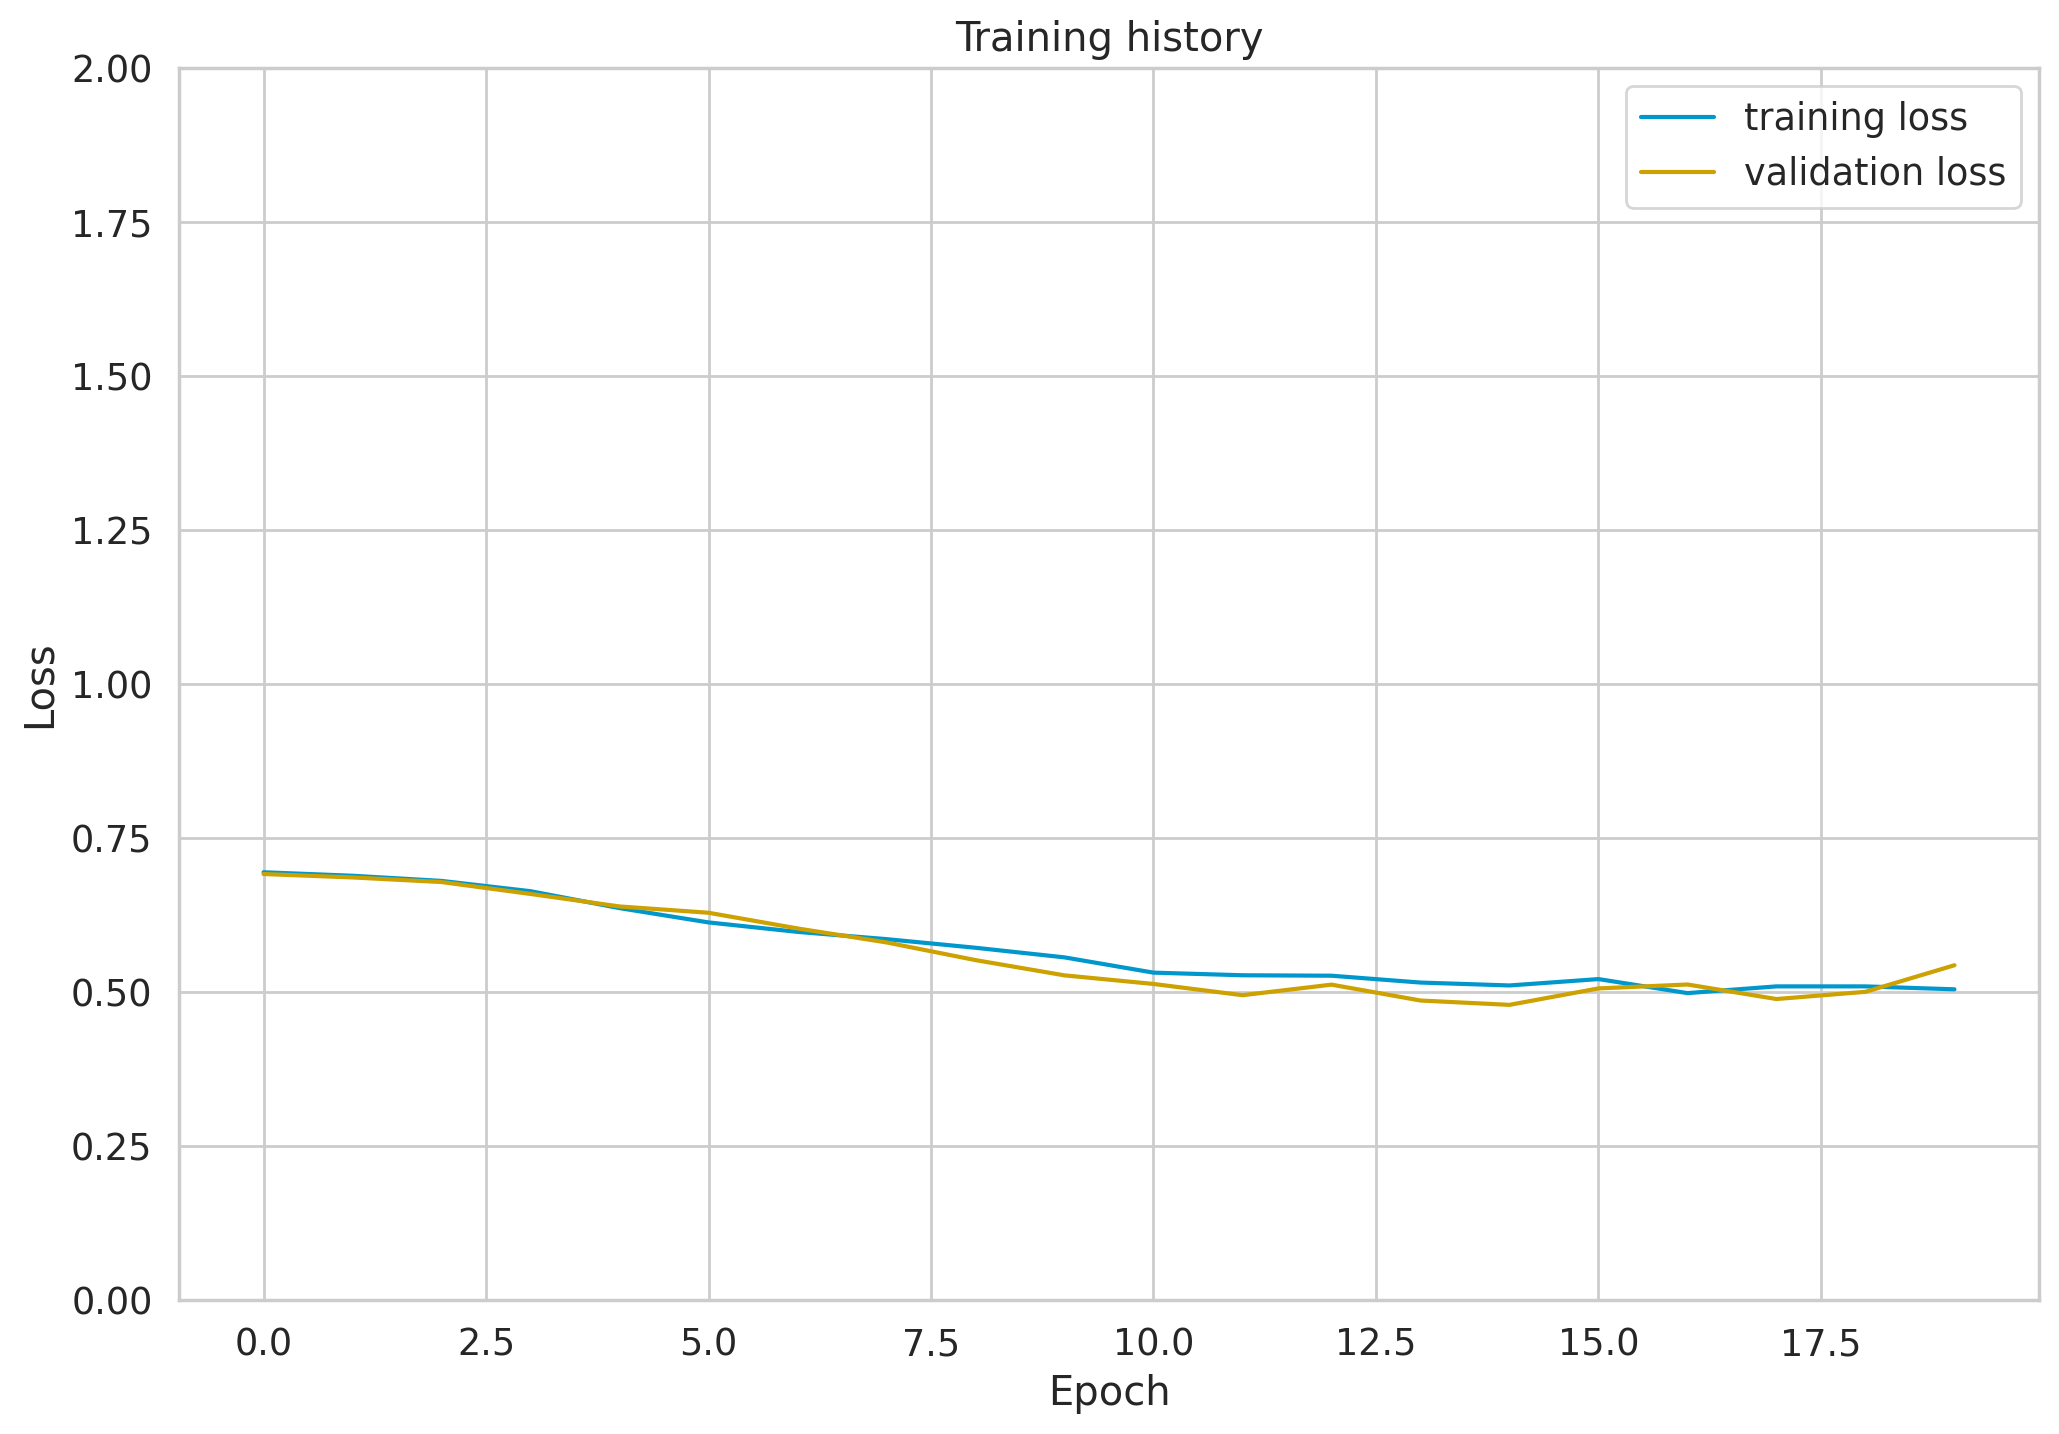

In [50]:
plt.plot(history['train_loss'], label='training loss')
plt.plot(history['test_loss'], label='validation loss')

plt.title('Training history')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.ylim([0, 2]);

### Model Evaluation

In [51]:
# Carrega os melhores pesos encontrados durante o treinamento para avaliação
if 'best_model_weights' in locals() and best_model_weights is not None:
    model.load_state_dict(best_model_weights)
    print("Melhores pesos do modelo carregados para avaliação!")

test_acc, test_loss, test_prec, test_rec, test_f1 = eval_model(
  model,
  test_data_loader,
  loss_fn,
  device,
  len(df_test)
)

print(f"Test Accuracy: {test_acc:.2f}")
print(f"Test Precision: {test_prec:.2f}")
print(f"Test Recall: {test_rec:.2f}")
print(f"Test F1: {test_f1:.2f}")


Melhores pesos do modelo carregados para avaliação!
Test Accuracy: 0.79
Test Precision: 0.80
Test Recall: 0.79
Test F1: 0.79


Define a helper function to get predictions from our models. This is similar to the evaluation function, except that we’re storing the text of the reviews and the predicted probabilities

In [52]:
def get_predictions(model, data_loader):
    model = model.eval()

    report_texts = []
    predictions = []
    prediction_probs = []
    real_values = []

    with torch.no_grad():
        for d in data_loader:
            texts = d["report_text"]
            input_ids = d["input_ids"].to(device)
            attention_mask = d["attention_mask"].to(device)
            targets = d["targets"].to(device)

            # Get outputs
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
            _, preds = torch.max(outputs, dim=1)

            report_texts.extend(texts)
            predictions.extend(preds)
            prediction_probs.extend(outputs)
            real_values.extend(targets)

    predictions = torch.stack(predictions).cpu()
    prediction_probs = torch.stack(prediction_probs).cpu()
    real_values = torch.stack(real_values).cpu()

    return report_texts, predictions, prediction_probs, real_values

In [53]:
y_report_texts, y_pred, y_pred_probs, y_test = get_predictions(
    model,
    test_data_loader
)

In [54]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=class_names))

                     precision    recall  f1-score   support

Desfavorável ao Réu       0.78      0.86      0.82       700
   Favorável ao Réu       0.81      0.72      0.77       605

           accuracy                           0.79      1305
          macro avg       0.80      0.79      0.79      1305
       weighted avg       0.80      0.79      0.79      1305



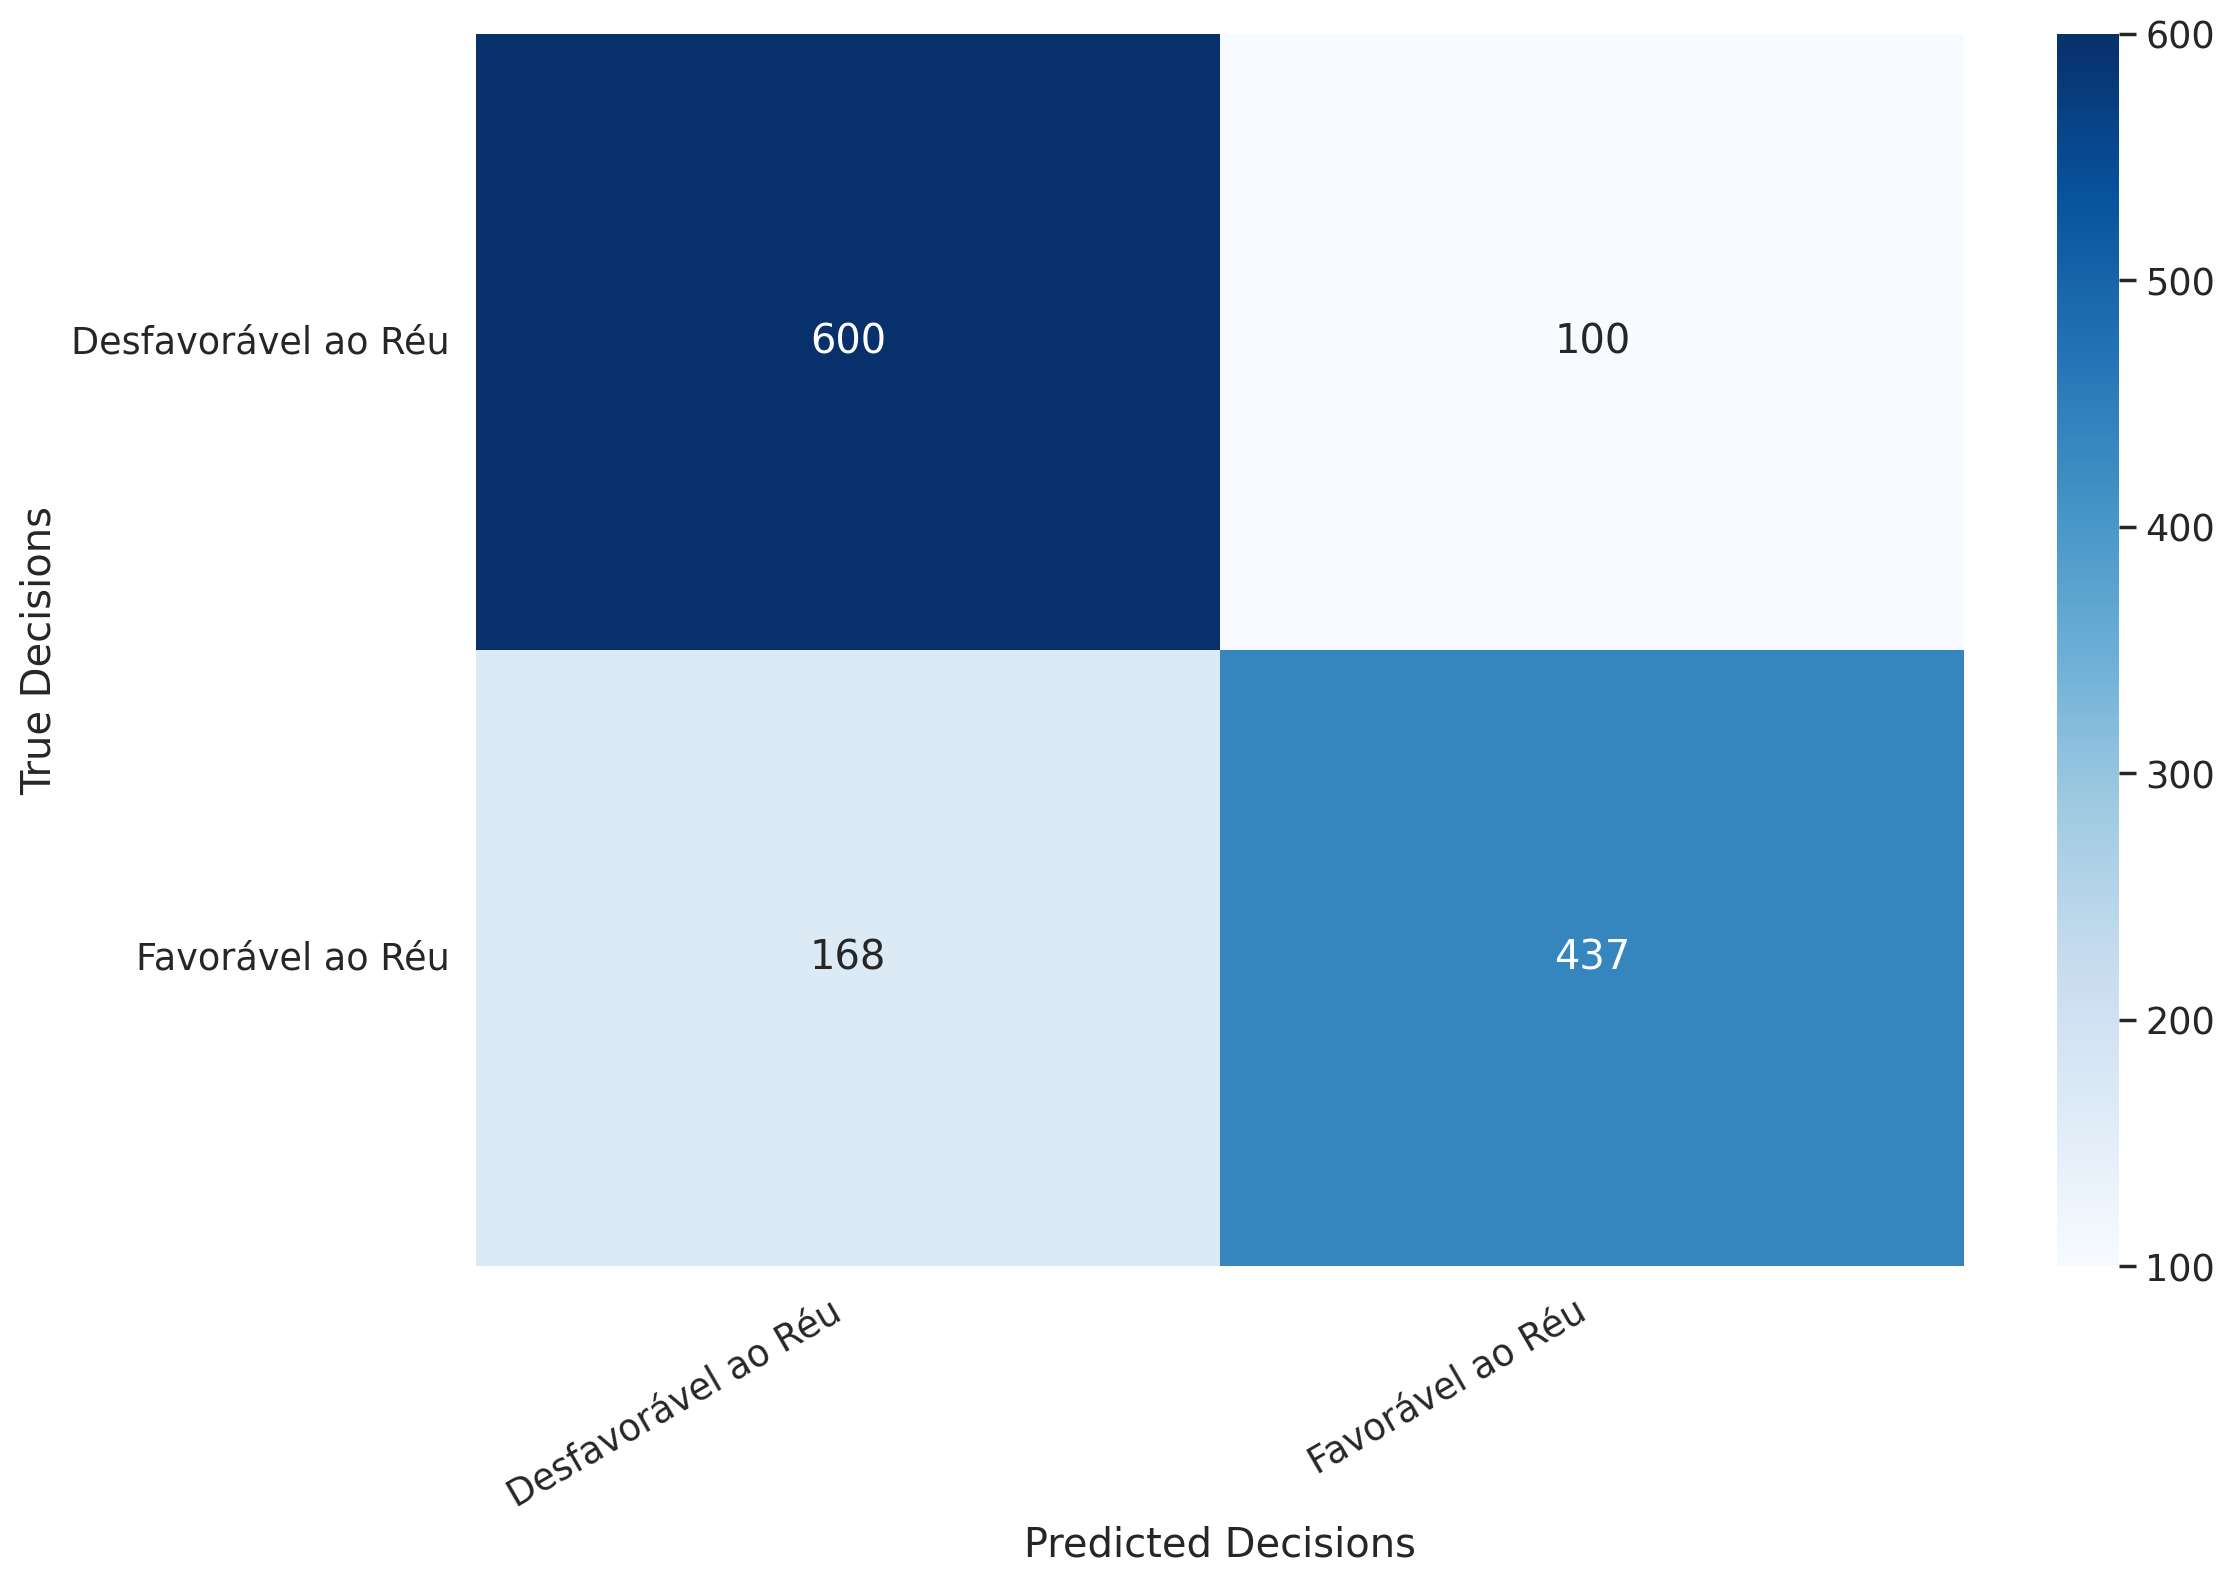

In [60]:
from sklearn.metrics import confusion_matrix

def show_confusion_matrix(confusion_matrix):
    hmap = sns.heatmap(confusion_matrix, annot=True, fmt="d", cmap="Blues")
    hmap.yaxis.set_ticklabels(hmap.yaxis.get_ticklabels(), rotation=0, ha='right')
    hmap.xaxis.set_ticklabels(hmap.xaxis.get_ticklabels(), rotation=30, ha='right')
    plt.ylabel('True Decisions')
    plt.xlabel('Predicted Decisions');

cm = confusion_matrix(y_test, y_pred)
df_cm = pd.DataFrame(cm, index=class_names, columns=class_names)
show_confusion_matrix(df_cm)

### Curva ROC e Métrica AUC
Avaliando a capacidade do modelo de distinguir entre as classes.

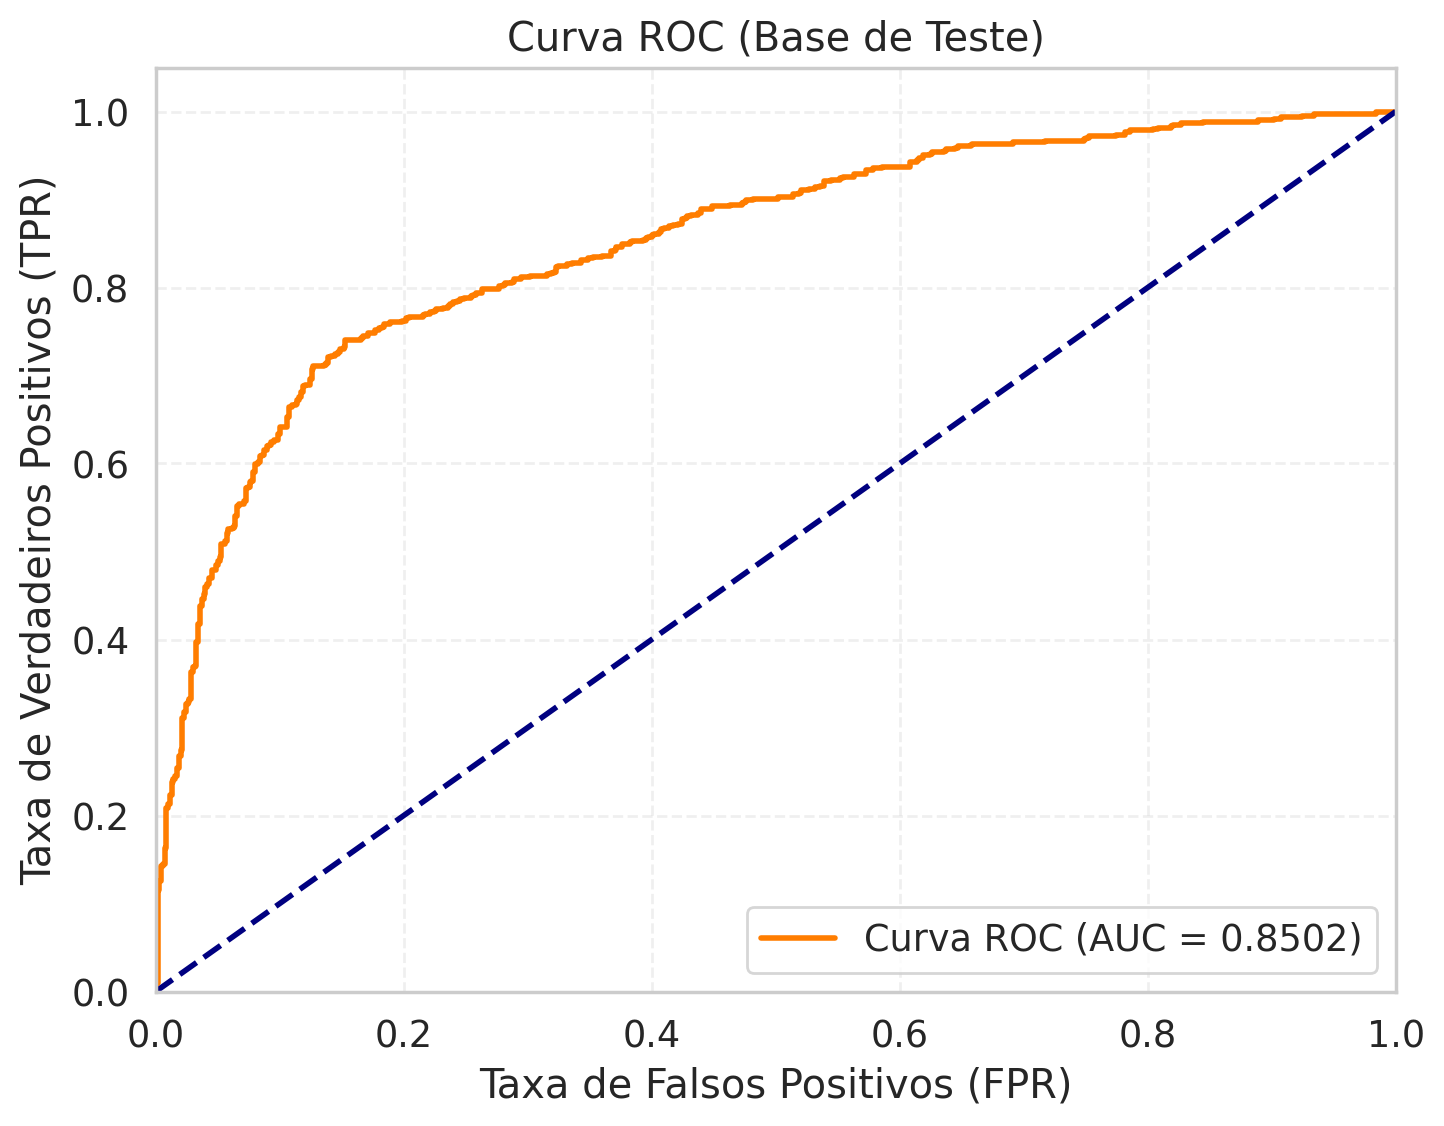

Métrica AUC: 0.8502


In [56]:
import torch.nn.functional as F
from sklearn.metrics import roc_curve, auc

# 1. Preparar os dados reais e as probabilidades
# y_test já contém as classes reais geradas pela função get_predictions (0 ou 1)
y_true = y_test.numpy()

# Converter logits (saídas brutas) em probabilidades para a classe positiva (1 - Favorável)
probs = F.softmax(y_pred_probs, dim=1).numpy()
y_scores = probs[:, 1] # Pegando apenas a probabilidade da classe 1

# 2. Calcular FPR (Taxa de Falsos Positivos) e TPR (Taxa de Verdadeiros Positivos)
fpr, tpr, thresholds = roc_curve(y_true, y_scores)

# 3. Calcular a Área Sob a Curva (AUC)
roc_auc = auc(fpr, tpr)

# 4. Plotar a Curva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='#FF7D00', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')

# Plotar a linha de base (modelo aleatório)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--',)

# Configurações do gráfico
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Curva ROC (Base de Teste)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3, linestyle='--')

plt.show()

print(f"Métrica AUC: {roc_auc:.4f}")

## Predicting on raw text

In [57]:
def BERT_SA(text) :
    encoded_review = tokenizer(text,
                              max_length=MAX_LEN,add_special_tokens=True,
                              return_token_type_ids=False,pad_to_max_length=True,
                              return_attention_mask=True,return_tensors='pt')

    input_ids = encoded_review['input_ids'].to(device)
    attention_mask = encoded_review['attention_mask'].to(device)

    # Garante que o modelo está no modo de avaliação e economiza memória
    model.eval()
    with torch.no_grad():
        output = model(input_ids, attention_mask)

    # Calcula as probabilidades usando softmax
    probs = F.softmax(output, dim=1)[0]
    _, prediction = torch.max(output, dim=1)

    print(f'Report: {text}\n')
    print(f'Decision  : {class_names[prediction]}')
    print('Probabilidades:')
    print(f' - {class_names[0]}: {probs[0].item() * 100:.2f}%')
    print(f' - {class_names[1]}: {probs[1].item() * 100:.2f}%')

In [58]:
def bert_vall(text, valor_real, model):
    encoded_review = tokenizer(text,
                              max_length=MAX_LEN, add_special_tokens=True,
                              return_token_type_ids=False, pad_to_max_length=True,
                              return_attention_mask=True, return_tensors='pt')

    input_ids = encoded_review['input_ids'].to(device)
    attention_mask = encoded_review['attention_mask'].to(device)

    # Garante que o modelo está no modo de avaliação e economiza memória
    model.eval()
    with torch.no_grad():
        output = model(input_ids, attention_mask)

    # Calcula as probabilidades usando softmax
    probs = F.softmax(output, dim=1)[0]
    prob_desfavoravel = probs[0].item()
    prob_favoravel = probs[1].item()

    # Obtém a classe prevista
    _, prediction = torch.max(output, dim=1)
    predicted_class_idx = prediction.item()
    predicted_class_name = class_names[predicted_class_idx]

    # Compara o valor previsto com o valor real passado
    # Permite comparar passando tanto o int (0 ou 1) quanto a string ('Favorável ao Réu' etc)
    if isinstance(valor_real, int):
        acertou = (predicted_class_idx == valor_real)
    else:
        acertou = (predicted_class_name == valor_real)

    return acertou, prob_desfavoravel, prob_favoravel

# Exemplo de uso:
# acertou, prob_desf, prob_fav = bert_vall("texto do relatorio...", 1, loaded_model)
# print(f"Acertou? {acertou} | Prob. Desfavorável: {prob_desf*100:.2f}% | Prob. Favorável: {prob_fav*100:.2f}%")

In [59]:
# texto = """<br>O ministro relator (SEBASTIÃO REIS): Trata-se de habeas: corpus <b>substitutivo de recurso próprio</b>, com pedido de liminar, impetrado em favor de LUIS FELIPE SILVA DE ASSIS, em que se aponta com autoridade coatora o Tribunal de Justiça do Estado do Rio de Janeiro.Consta dos autos que o paciente foi condenado à pena de 5 anos e 10 meses de reclusão, em regime semiaberto, mais pagamento de 583 dias-multa, como incurso no art. 33,caput, c.c o 40, VI, da Lei n. 11.343/2006.Em sede recursal, o Tribunal de origem negou provimento ao apelo defensivo."""
# texto = pre_processamento(texto, mantem_pontuacao='n')

# BERT_SA(texto)